In [1]:
!git clone https://github.com/Tralaiday/NLP.git temp_repo

import sys
import os

src_path = os.path.abspath('temp_repo/Lab6/src')
if src_path not in sys.path:
    sys.path.append(src_path)

print("Đã cấu hình đường dẫn import thành công từ:", src_path)

Cloning into 'temp_repo'...
remote: Enumerating objects: 173, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 173 (delta 0), reused 0 (delta 0), pack-reused 168 (from 1)
Receiving objects: 100% (173/173), 58.94 MiB | 20.21 MiB/s, done.
Resolving deltas: 100% (47/47), done.
Updating files: 100% (57/57), done.
Đã cấu hình đường dẫn import thành công từ: /content/temp_repo/Lab6/src


In [2]:
# 1. Đi vào thư mục repo và kéo (pull) code mới nhất về
!git -C temp_repo pull

# 2. Reload module trong Python để áp dụng thay đổi mới ngay lập tức
import importlib
import attention_numpy

importlib.reload(attention_numpy)
from attention_numpy import scaled_dot_product_attention

print("Đã cập nhật và nạp lại mô-đun 'attention_numpy' thành công!")

Already up to date.
Đã cập nhật và nạp lại mô-đun 'attention_numpy' thành công!


In [3]:
!cd temp_repo/Lab6/src
!git pull origin main

fatal: not a git repository (or any of the parent directories): .git


In [15]:
from attention_numpy import scaled_dot_product_attention
from collections import Counter
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

# Experiment 1: Attention distribution

In [5]:
query_tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]

# Embeddings: [sentiment, topic, context/time]
embedding_dict = {
    "The": [0.0, 0.0, 0.1],
    "movie": [0.1, 1.0, 0.2],
    "was": [0.0, 0.0, 0.0],
    "surprisingly": [0.5, 0.2, 0.1],
    "good": [1.0, 0.3, 0.1],
    "despite": [0.0, 0.1, 0.5],
    "a": [0.0, 0.0, 0.0],
    "very": [0.2, 0.1, 0.0],
    "slow": [-0.8, 0.2, 0.2],
    "beginning": [-0.1, 0.2, 1.0]
}
print("Number of tokens:", len(query_tokens))

# Tạo K
K = np.array([embedding_dict[token] for token in query_tokens], dtype = float)

# Tạo Q
Q = np.array([1.0, 0.0, 0.0], dtype = float)

# Tạo V
V = K.copy()

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

S, A = scaled_dot_product_attention(Q, K, V)[:2]

df_experiment_1 = pd.DataFrame(
    {
        "Token": query_tokens,
        "Score": S,
        "Attention": A
    }
)

print(df_experiment_1)


Number of tokens: 10
Q shape: (3,)
K shape: (10, 3)
V shape: (10, 3)
          Token     Score  Attention
0           The  0.000000   0.091981
1         movie  0.057735   0.097448
2           was  0.000000   0.091981
3  surprisingly  0.288675   0.122763
4          good  0.577350   0.163847
5       despite  0.000000   0.091981
6             a  0.000000   0.091981
7          very  0.115470   0.103240
8          slow -0.461880   0.057957
9     beginning -0.057735   0.086821


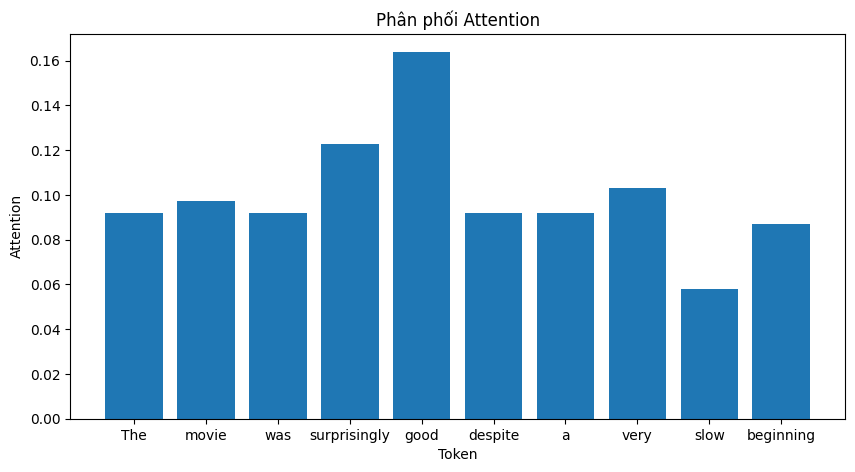

In [6]:
plt.figure(figsize = (10, 5))
plt.bar(query_tokens, A)

plt.title("Phân phối Attention")
plt.xlabel("Token")
plt.ylabel("Attention")
plt.show()

# Experiment 2: Query thay đổi

          Token     Score  Attention
0           The  0.000000   0.087287
1         movie  0.577350   0.155485
2           was  0.000000   0.087287
3  surprisingly  0.115470   0.097971
4          good  0.173205   0.103794
5       despite  0.057735   0.092475
6             a  0.000000   0.087287
7          very  0.057735   0.092475
8          slow  0.115470   0.097971
9     beginning  0.115470   0.097971


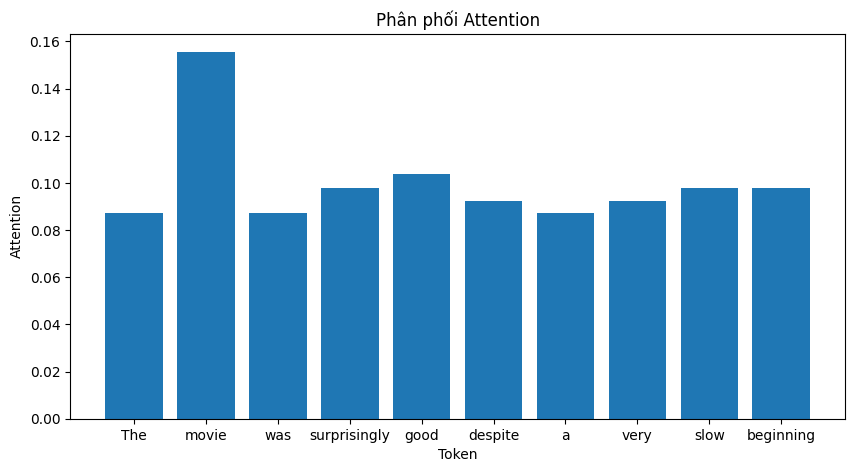

In [7]:
new_Q = np.array([0.0, 1.0, 0.0], dtype = float)

new_S, new_A = scaled_dot_product_attention(new_Q, K, V)[:2]

df_experiment_2 = pd.DataFrame(
    {
        "Token": query_tokens,
        "Score": new_S,
        "Attention": new_A
    }
)

print(df_experiment_2)

plt.figure(figsize = (10, 5))
plt.bar(query_tokens, new_A)

plt.title("Phân phối Attention")
plt.xlabel("Token")
plt.ylabel("Attention")
plt.show()

# Experiment 3: Attention visualization

In [8]:
sentence_1 = ["The", "cat", "that", "I", "adopted", "yesterday", "is", "sleeping"]
sentence_2 = ["The", "book", "that", "I", "bought", "yesterday", "was", "expensive"]

rng = np.random.default_rng(42)

all_tokens = sorted(set(sentence_1 + sentence_2))

embedding_dim = 8
embedding_table = {
    token: rng.normal(0.0, 1.0, embedding_dim)
    for token in all_tokens
}

X1 = np.array(
    [embedding_table[token] for token in sentence_1],
    dtype = float
)

X2 = np.array(
    [embedding_table[token] for token in sentence_2],
    dtype = float
)

Q1, K1, V1 = X1, X1, X1
Q2, K2, V2 = X2, X2, X2

scores_1, attention_1, context_1 = (
    scaled_dot_product_attention(Q1, K1, V1)
)

scores_2, attention_2, context_2 = (
    scaled_dot_product_attention(Q2, K2, V2)
)

print(attention_1.sum(axis=1))
print(attention_2.sum(axis=1))

assert np.all(attention_1 >= 0)
assert np.all(attention_2 >= 0)

assert attention_1.shape == (len(sentence_1), len(sentence_1))
assert attention_2.shape == (len(sentence_2), len(sentence_2))

[1. 1. 1. 1. 1. 1. 1. 1.]
[1. 1. 1. 1. 1. 1. 1. 1.]


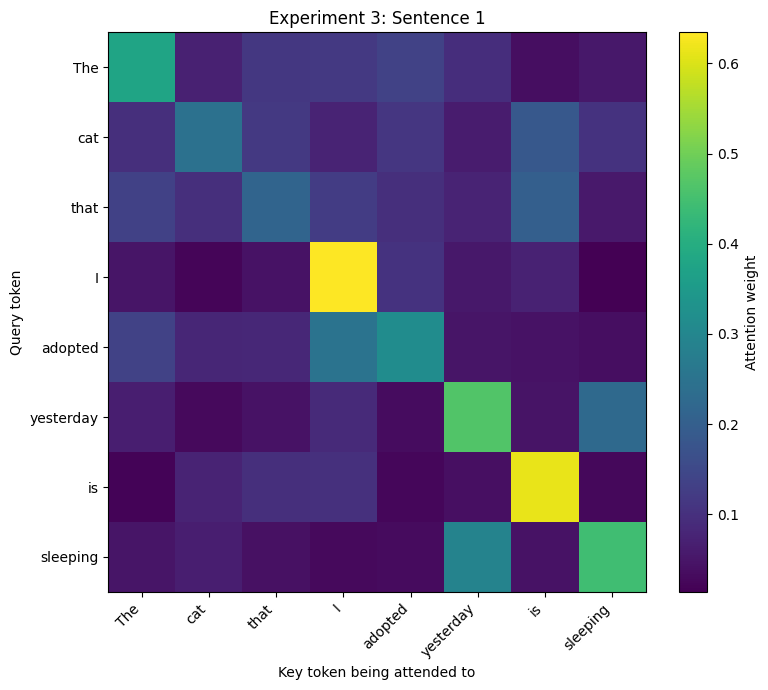

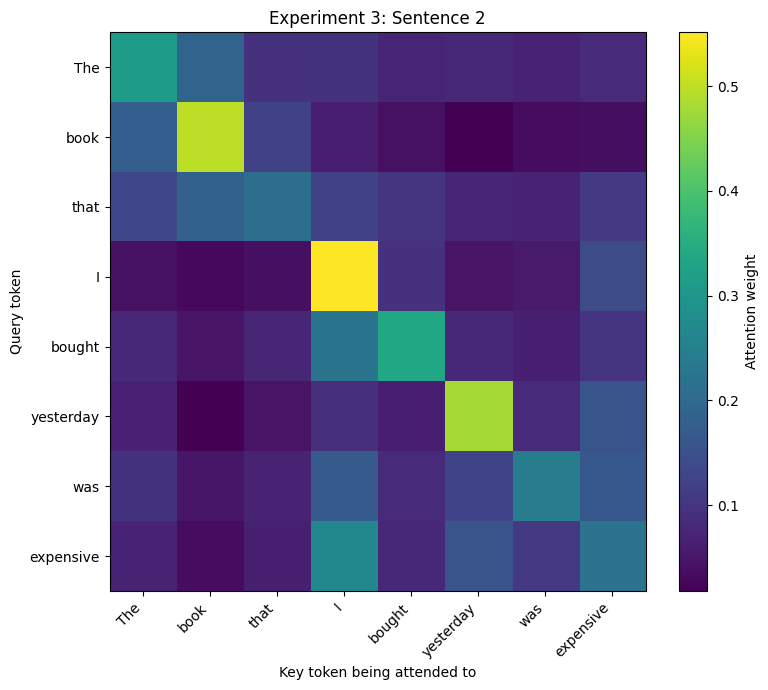

In [9]:
def plot_attention_heatmap(attention, tokens, title):
    fig, ax = plt.subplots(figsize=(8, 7))

    image = ax.imshow(
        attention,
        cmap="viridis",
        aspect="auto"
    )

    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))

    ax.set_xticklabels(tokens, rotation=45, ha="right")
    ax.set_yticklabels(tokens)

    ax.set_xlabel("Key token being attended to")
    ax.set_ylabel("Query token")
    ax.set_title(title)

    fig.colorbar(image, ax=ax, label="Attention weight")
    fig.tight_layout()
    plt.show()

plot_attention_heatmap(
    attention_1,
    sentence_1,
    "Experiment 3: Sentence 1"
)

plot_attention_heatmap(
    attention_2,
    sentence_2,
    "Experiment 3: Sentence 2"
)

In [10]:
selected_tokens = ["cat", "adopted", "sleeping"]

for token in selected_tokens:
    query_index = sentence_1.index(token)
    row = attention_1[query_index]

    print(f"\nQuery token: {token}")

    for key_index in np.argsort(row)[::-1]:
        print(
            f"  attends to {sentence_1[key_index]:>10}: "
            f"{row[key_index]:.4f}"
        )


Query token: cat
  attends to        cat: 0.2460
  attends to         is: 0.1852
  attends to       that: 0.1170
  attends to    adopted: 0.1131
  attends to   sleeping: 0.1039
  attends to        The: 0.0972
  attends to          I: 0.0764
  attends to  yesterday: 0.0611

Query token: adopted
  attends to    adopted: 0.3166
  attends to          I: 0.2497
  attends to        The: 0.1367
  attends to       that: 0.0830
  attends to        cat: 0.0818
  attends to  yesterday: 0.0501
  attends to         is: 0.0446
  attends to   sleeping: 0.0374

Query token: sleeping
  attends to   sleeping: 0.4452
  attends to  yesterday: 0.2912
  attends to        cat: 0.0665
  attends to        The: 0.0481
  attends to         is: 0.0437
  attends to       that: 0.0427
  attends to    adopted: 0.0331
  attends to          I: 0.0294


# Experiment 4: RNN context vs Attention context

In [14]:
data = pd.read_csv('temp_repo/Lab6/data/IMDB Dataset.csv')

df = data[["review", "sentiment"]].copy()
df['sentiment'] = [1 if sentiment == 'positive' else 0 for sentiment in df['sentiment']]

# Kiểm tra review bị trùng trong dataset
duplicate_reviews = df.duplicated(
    subset=["review"],
    keep="first"
)
print("Số review trùng:", duplicate_reviews.sum())

# Thống kê số review bị trùng nhưng khác nhãn
conflicting_labels = (
    df.groupby("review")["sentiment"]
      .nunique()
      .gt(1)
)
print(
    "Số review trùng nhưng khác nhãn:",
    conflicting_labels.sum()
)

# Loại bỏ duplicates trong bộ dataset
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Thống kê sơ bộ về dataset
print(f'Số sample: {len(df)}')
print(f'Số classes: {df['sentiment'].nunique()}')

class_distribution = pd.DataFrame({
    'Count': df['sentiment'].value_counts(),
    'Percentage (%)': df['sentiment'].value_counts(normalize=True) * 100
})
print('Phân phối class trên tập dataset: ')
print(class_distribution)

# Chia train/val/test
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Số review trùng: 418
Số review trùng nhưng khác nhãn: 0
Số sample: 49582
Số classes: 2
Phân phối class trên tập dataset: 
           Count  Percentage (%)
sentiment                       
1          24884       50.187568
0          24698       49.812432
Train: 39665
Validation: 4958
Test: 4959


In [16]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

MAX_VOCAB_SIZE = 10_000
MAX_LENGTH = 100


def tokenize(text):
    text = text.lower()
    text = text.replace("<br />", " ")
    return re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", text)


# Chỉ xây vocabulary từ train
token_counts = Counter(
    token
    for review in train_df["review"]
    for token in tokenize(review)
)

vocabulary = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1,
}

for token, _ in token_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocabulary[token] = len(vocabulary)

print("Vocabulary size:", len(vocabulary))

Vocabulary size: 10000
